# Laboratorio 10: explicabilidad de M1e (Serve Lab)

Este notebook regenera todas las figuras y tablas de `docs/laboratorio-10.md` con semilla fija.

Explica **M1e**, el modelo que usa la app para decidir si el brazo que lanza la pelota baja antes de tiempo. Usa **Integrated Gradients** (captum) sobre el modelo ya entrenado, sin reentrenarlo.

Para ejecutarlo, desde la raíz del repositorio:

```
uv sync --group xai
uv run --group xai jupyter nbconvert --to notebook --execute --inplace xai/explicabilidad.ipynb
```

Necesita `data/processed/serve_dataset.npz`, que genera `uv run python -m strokes.serve.dataset`. Los videos y los puntos del cuerpo de los jugadores son datos personales y no están en Git. Las figuras y tablas quedan en `xai/results/`.

In [1]:
import os
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm, imported by captum

# Run from the repository root, whether the kernel starts there or in xai/
ROOT = Path.cwd().parent if Path.cwd().name == "xai" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
OUT = ROOT / "xai" / "results"
OUT.mkdir(exist_ok=True)

In [2]:
import csv
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import yaml
from captum.attr import IntegratedGradients
from matplotlib.colors import LinearSegmentedColormap
from torch import nn

from eval import value as value_model
from strokes.serve import baseline, dataset
from strokes.serve import model as serve_model

%matplotlib inline

SEED = 0  # only the random order of the faithfulness check draws numbers; IG is deterministic
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

m1e = serve_model.load("m1e")  # the 5 seeds, the clean reference serve and the threshold
data = np.load(dataset.OUT)
THRESHOLD = m1e["threshold"]
print(f"M1e: {len(m1e['models'])} semillas, umbral {THRESHOLD:.5f}")


def save(name, rows):
    # One table of the report: xai/results/<name>.csv
    with open(OUT / f"{name}.csv", "w", newline="") as file:
        writer = csv.DictWriter(file, list(rows[0]), lineterminator="\n")
        writer.writeheader()
        writer.writerows(rows)


def r(value, digits=3):
    return round(float(value), digits)

M1e: 5 semillas, umbral 0.52581


## 1. El modelo como función de las alturas

M1e no ve el video. Ve 4 **alturas sobre el hombro**, en largos de torso, durante 64 cuadros (de 1.6 s antes del contacto a 0.5 s después, a 30 fps):

- el codo y la muñeca del brazo que lanza la pelota;
- el codo y la muñeca del brazo de la raqueta.

La red también recibe 4 canales de máscara que siempre valen 1 (`train.heights`). Por eso la envoltura los agrega por dentro y solo las alturas reciben atribución.

La salida es la probabilidad que la app compara con el umbral: la media de las 5 semillas.

In [3]:
HEIGHTS = ["codo que lanza", "muñeca que lanza", "codo de la raqueta", "muñeca de la raqueta"]
FRAMES = dataset.BEFORE + 1 + dataset.AFTER  # 64 frames, contact at frame 48
TIME = (np.arange(FRAMES) - dataset.BEFORE) / dataset.FPS  # seconds from contact


class Ensemble(nn.Module):
    # P(drops early) from (N, 4, 64) heights: mean over seeds of each network's sigmoid
    def __init__(self, models):
        super().__init__()
        self.models = nn.ModuleList(models)

    def forward(self, heights):
        x = torch.cat([heights, torch.ones_like(heights)], 1)  # the 4 mask channels, all seen
        return torch.stack([torch.sigmoid(m(x).squeeze(1)) for m in self.models]).mean(0)


f = Ensemble(m1e["models"]).eval()


def heights(chosen):
    # (N, 4, 64) model input of the dataset windows `chosen`
    h, _ = serve_model.inputs(m1e, data["x"][chosen], data["mask"][chosen])
    return torch.from_numpy(h[..., 0].astype(np.float32)).transpose(1, 2)


# Baseline of IG: the mean window of the train serves without the fault (saved with M1e)
reference = torch.from_numpy(m1e["reference"][..., 0].astype(np.float32)).T[None]

test = (data["valid"] == 1) & (data["split"] == "test")
video = data["video"][test].astype(str)
truth = data["category"][test] == baseline.POSITIVE
x_test = heights(test)
with torch.no_grad():
    p_test = f(x_test).numpy()
    p_reference = f(reference).item()
flagged = p_test >= THRESHOLD

# The same probabilities the project reported (experiments/serve/m1e.csv, mean of the seeds)
scores = [row for row in csv.DictReader((baseline.RESULTS / "m1e.csv").open())
          if row["split"] == "test"]
reported = {v: np.mean([float(row["score"]) for row in scores if row["video"] == v])
            for v in video}
assert np.allclose(p_test, [reported[v] for v in video], atol=1e-4)
print(f"{test.sum()} saques de prueba, {truth.sum()} con la falla; "
      f"P del saque limpio de referencia = {p_reference:.3f}")

18 saques de prueba, 13 con la falla; P del saque limpio de referencia = 0.472


## 2. Integrated Gradients

IG suma los gradientes de P a lo largo de la recta que va del saque limpio de referencia $x'$ al saque $x$:

$$\mathrm{IG}_i(x) = (x_i - x'_i)\int_0^1 \frac{\partial P(x' + \alpha (x - x'))}{\partial x_i}\, d\alpha$$

Cada celda (altura, cuadro) recibe una atribución:

- **positiva** si empuja hacia "baja antes de tiempo";
- **negativa** si empuja hacia un saque limpio.

**Completitud:** las atribuciones suman exactamente $P(x) - P(x')$. El `assert` lo comprueba con el error de la integral numérica.

**Parámetros:**

- **Línea base: el saque limpio de referencia.** Es la misma que usa la oclusión de la app, y la pregunta que responde es la del entrenador: ¿qué tiene este saque distinto de uno limpio?
- **64 pasos de Gauss-Legendre.**

La sección 6 mide cuánto cambia la explicación con otros valores.

In [4]:
N_STEPS = 64
ig = IntegratedGradients(f)


def attribute(x, base=reference, n_steps=N_STEPS):
    # (N, 4, 64) attributions and, per window, sum - (P(x) - P(base)): the completeness error
    a, delta = ig.attribute(x, baselines=base, n_steps=n_steps, method="gausslegendre",
                            return_convergence_delta=True)
    return a.detach().numpy(), delta.detach().numpy()


a_test, delta = attribute(x_test)
assert np.abs(delta).max() < 0.01
print(f"Máximo |Σ atribuciones − (P(x) − P(limpio))| = {np.abs(delta).max():.5f}")

Máximo |Σ atribuciones − (P(x) − P(limpio))| = 0.00043


## 3. Cinco explicaciones locales

Las 5 instancias del conjunto de prueba salen de una regla en el código, no se eligen a mano:

1. **Acierto seguro:** el saque con la falla de mayor P.
2. **Error:** la falsa alarma de mayor P. M1e no omite ningún saque con la falla en prueba; sus errores son saques limpios de JC.
3. **Cerca del umbral:** el saque con P más cercana a 0.526.
4. **Falsa alarma cerca del umbral:** su par del otro lado de la verdad, para ver qué los distingue.
5. **Subgrupo:** el profesional de prueba (pro01) con menor P, un jugador que el modelo nunca vio.

En los mapas:

- **naranja** empuja hacia la falla y **azul** hacia un saque limpio;
- la línea punteada marca el contacto.

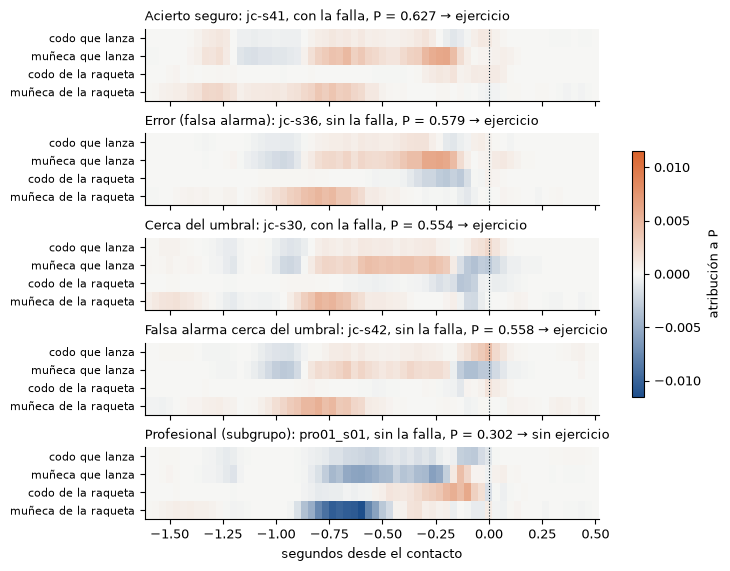

{'caso': 'Acierto seguro', 'video': 'jc-s41', 'verdad': 'con la falla', 'p': 0.627, 'decision': 'ejercicio', 'brazo_que_lanza': 0.088, 'brazo_de_raqueta': 0.067, 'suma': 0.155}
{'caso': 'Error (falsa alarma)', 'video': 'jc-s36', 'verdad': 'sin la falla', 'p': 0.579, 'decision': 'ejercicio', 'brazo_que_lanza': 0.075, 'brazo_de_raqueta': 0.032, 'suma': 0.107}
{'caso': 'Cerca del umbral', 'video': 'jc-s30', 'verdad': 'con la falla', 'p': 0.554, 'decision': 'ejercicio', 'brazo_que_lanza': 0.058, 'brazo_de_raqueta': 0.025, 'suma': 0.083}
{'caso': 'Falsa alarma cerca del umbral', 'video': 'jc-s42', 'verdad': 'sin la falla', 'p': 0.558, 'decision': 'ejercicio', 'brazo_que_lanza': 0.025, 'brazo_de_raqueta': 0.061, 'suma': 0.086}
{'caso': 'Profesional (subgrupo)', 'video': 'pro01_s01', 'verdad': 'sin la falla', 'p': 0.302, 'decision': 'sin ejercicio', 'brazo_que_lanza': -0.115, 'brazo_de_raqueta': -0.055, 'suma': -0.17}


In [5]:
CMAP = LinearSegmentedColormap.from_list("serve", ["#1e4f8c", "#f7f7f5", "#d9622b"])
EXTENT = (TIME[0] - 0.5 / dataset.FPS, TIME[-1] + 0.5 / dataset.FPS, 3.5, -0.5)


def heatmap(ax, a, limit, title):
    # One (4, 64) map: orange pushes toward "drops early", blue away from it
    image = ax.imshow(a, cmap=CMAP, vmin=-limit, vmax=limit, aspect="auto", extent=EXTENT)
    ax.axvline(0, color="#0b1f2a", lw=0.8, ls=":")
    ax.set_yticks(range(4), HEIGHTS, fontsize=8)
    ax.set_title(title, fontsize=9, loc="left")
    return image


def pick(chosen, score):
    # Index of the window `chosen` with the highest score
    where = np.flatnonzero(chosen)
    return where[np.argmax(score[where])]


near = -np.abs(p_test - THRESHOLD)
false_alarm = flagged & ~truth
error = pick(false_alarm, p_test)
cases = {
    "Acierto seguro": pick(truth & flagged, p_test),
    "Error (falsa alarma)": error,
    "Cerca del umbral": pick(np.ones(len(p_test), bool), near),
    "Falsa alarma cerca del umbral": pick(false_alarm & (np.arange(len(p_test)) != error), near),
    "Profesional (subgrupo)": pick(np.char.startswith(video, "pro"), -p_test),
}
assert len(set(cases.values())) == 5

limit = np.abs(a_test[list(cases.values())]).max()
fig, axes = plt.subplots(5, 1, figsize=(7.2, 5.6), sharex=True, constrained_layout=True)
rows = []
for ax, (case, i) in zip(axes, cases.items()):
    label = "con la falla" if truth[i] else "sin la falla"
    decision = "ejercicio" if flagged[i] else "sin ejercicio"
    image = heatmap(ax, a_test[i], limit,
                    f"{case}: {video[i]}, {label}, P = {p_test[i]:.3f} → {decision}")
    rows.append({"caso": case, "video": str(video[i]), "verdad": label, "p": r(p_test[i]),
                 "decision": decision, "brazo_que_lanza": r(a_test[i, :2].sum()),
                 "brazo_de_raqueta": r(a_test[i, 2:].sum()), "suma": r(a_test[i].sum())})
axes[-1].set_xlabel("segundos desde el contacto")
fig.colorbar(image, ax=axes, shrink=0.5, label="atribución a P")
fig.savefig(OUT / "local.png", dpi=200)
plt.show()
save("instancias", rows)
for row in rows:
    print(row)

## 4. Explicación global

La figura promedia las atribuciones con signo de los 18 saques de prueba por grupo: JC con la falla, JC sin la falla y el profesional.

La tabla `global.csv` suma cada mapa en los 8 tramos de 0.27 s que usa la oclusión de la app.

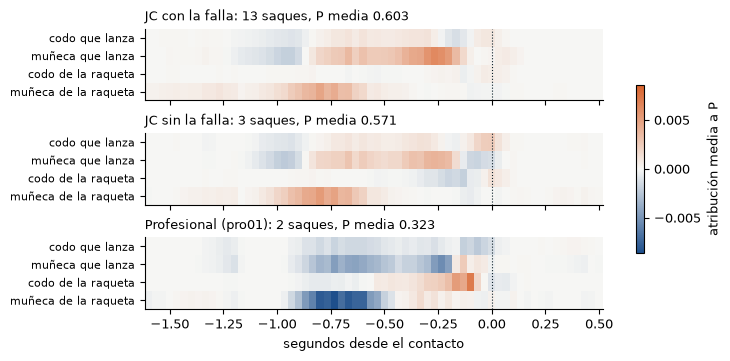

{'grupo': 'Profesional (pro01)', 'altura': 'muñeca de la raqueta', 'desde_s': -0.8, 'atribucion': -0.0589}
{'grupo': 'Profesional (pro01)', 'altura': 'muñeca que lanza', 'desde_s': -0.8, 'atribucion': -0.0301}
{'grupo': 'JC con la falla', 'altura': 'muñeca que lanza', 'desde_s': -0.53, 'atribucion': 0.0297}
{'grupo': 'JC sin la falla', 'altura': 'muñeca de la raqueta', 'desde_s': -0.8, 'atribucion': 0.0274}
{'grupo': 'Profesional (pro01)', 'altura': 'codo de la raqueta', 'desde_s': -0.27, 'atribucion': 0.0268}
{'grupo': 'JC con la falla', 'altura': 'muñeca de la raqueta', 'desde_s': -0.8, 'atribucion': 0.0237}
{'grupo': 'JC con la falla', 'altura': 'muñeca que lanza', 'desde_s': -0.27, 'atribucion': 0.0233}
{'grupo': 'JC sin la falla', 'altura': 'muñeca de la raqueta', 'desde_s': -1.07, 'atribucion': 0.0216}


In [6]:
def stretches(a):
    # (N, 4, 64) per-frame attributions summed over the 8 stretches of BIN frames: (N, 4, 8)
    return a.reshape(*a.shape[:2], -1, serve_model.BIN).sum(-1)


groups_test = {
    "JC con la falla": truth,
    "JC sin la falla": ~truth & np.char.startswith(video, "jc"),
    "Profesional (pro01)": np.char.startswith(video, "pro"),
}
means = {g: a_test[chosen].mean(0) for g, chosen in groups_test.items()}
limit = max(np.abs(mean).max() for mean in means.values())
fig, axes = plt.subplots(3, 1, figsize=(7.2, 3.5), sharex=True, constrained_layout=True)
rows = []
for ax, (g, chosen) in zip(axes, groups_test.items()):
    image = heatmap(ax, means[g], limit,
                    f"{g}: {chosen.sum()} saques, P media {p_test[chosen].mean():.3f}")
    for j, height in enumerate(HEIGHTS):
        for k, start in enumerate(serve_model.STARTS):
            rows.append({"grupo": g, "altura": height, "desde_s": r(TIME[start], 2),
                         "atribucion": r(stretches(means[g][None])[0, j, k], 4)})
axes[-1].set_xlabel("segundos desde el contacto")
fig.colorbar(image, ax=axes, shrink=0.6, label="atribución media a P")
fig.savefig(OUT / "global.png", dpi=200)
plt.show()
save("global", rows)
for row in sorted(rows, key=lambda row: -abs(row["atribucion"]))[:8]:  # the stretches that weigh most
    print(row)

## 5. ¿Atajos, fugas o variables proxy?

Se revisan tres cosas en prueba y en los saques `new`, que el modelo nunca vio (EA, JC después de la sesión y profesionales nuevos):

1. **Fuga en el tiempo.** Cuánta atribución cae después del contacto. Lo que pasa después no puede causar la falla.
2. **Identidad por la postura.** Cuánta cae en los primeros 0.53 s, antes del lanzamiento, cuando el jugador solo está parado. Si fuera alta, el modelo estaría reconociendo a la persona.
3. **Proxy de JC por el brazo de la raqueta.** Cuánto empuja cada brazo en cada grupo.

Después se prueban dos cambios que no reentrenan el modelo:

- **Sin raqueta:** el brazo de la raqueta se mueve como el saque limpio y se cuentan los saques que siguen marcados.
- **Regla "En duda":** un saque marcado pasa a "En duda" en lugar de recibir el ejercicio cuando su brazo de la raqueta empuja más que el brazo que lanza.

La regla salió de mirar estas explicaciones en prueba. "JC después de la sesión" son 44 saques limpios que no se usaron para elegirla.

In [7]:
STANCE = slice(0, serve_model.STANCE)  # standing, before the toss
TOSS = slice(serve_model.STANCE, dataset.BEFORE + 1)  # toss and swing, up to contact
AFTER = slice(dataset.BEFORE + 1, FRAMES)  # after contact: cannot cause the fault

seen = (data["valid"] == 1) & (data["split"] != "train")
player = data["player"][seen].astype(str)
names = data["video"][seen].astype(str)
split = data["split"][seen]
fault = data["category"][seen] == baseline.POSITIVE
x_seen = heights(seen)
a_seen, _ = attribute(x_seen)
without_racket = x_seen.clone()
without_racket[:, 2:] = reference[:, 2:]  # the racket arm moves like the clean serve
with torch.no_grad():
    p_seen, p_without = f(x_seen).numpy(), f(without_racket).numpy()
tossing_arm, racket_arm = a_seen[:, :2].sum((1, 2)), a_seen[:, 2:].sum((1, 2))
marked_seen = p_seen >= THRESHOLD
doubt = marked_seen & (racket_arm > tossing_arm)  # the racket arm, not the toss, decides

groups = {
    "JC con la falla (prueba)": (split == "test") & fault,
    "JC sin la falla (prueba)": (split == "test") & (player == "jc") & ~fault,
    "pro01 (prueba)": player == "pro01",
    "JC después de la sesión (nuevo)": np.char.startswith(names, "jc-post"),
    "EA (nuevo)": player == "ea",
    "Profesionales nuevos": np.isin(player, ["pro04", "pro05", "yt2"]),
    "YouTube con la falla (nuevo)": player == "yt3",
}
rows = []
for g, chosen in groups.items():
    a = a_seen[chosen]
    total = np.abs(a).sum()
    rows.append({
        "grupo": g, "saques": int(chosen.sum()), "p_media": r(p_seen[chosen].mean()),
        "marcados": r(marked_seen[chosen].mean(), 2),
        "brazo_que_lanza": r(np.median(tossing_arm[chosen])),
        "brazo_de_raqueta": r(np.median(racket_arm[chosen])),
        "postura": r(np.abs(a[:, :, STANCE]).sum() / total, 2),
        "lanzamiento": r(np.abs(a[:, :, TOSS]).sum() / total, 2),
        "despues": r(np.abs(a[:, :, AFTER]).sum() / total, 2),
        "marcados_sin_raqueta": r((p_without[chosen] >= THRESHOLD).mean(), 2),
        "en_duda": r(doubt[chosen].mean(), 2),
        "ejercicio_con_regla": r((marked_seen & ~doubt)[chosen].mean(), 2),
    })
save("grupos", rows)
for row in rows:
    print(row)

# Value per analysis (eval/value.py, configs/value.yaml) with the ensemble's rates on test; a
# serve "En duda" gets no drill, so it counts as silence
config = yaml.safe_load(value_model.CONFIG.read_text())
on_test = split == "test"
rows = []
for name, said in (("M1e", marked_seen), ('M1e + regla "En duda"', marked_seen & ~doubt)):
    tpr, fpr = said[on_test & fault].mean(), said[on_test & ~fault].mean()
    rows.append({"version": name, "recall_prueba": r(tpr, 2), "falsas_alarmas_prueba": r(fpr, 2),
                 "valor_por_analisis": r(value_model.value(tpr, fpr, config,
                                                            config["pose_seconds"]), 2),
                 "falsas_alarmas_jc_despues": r(said[groups["JC después de la sesión (nuevo)"]]
                                                .mean(), 2),
                 "falsas_alarmas_ea": r(said[groups["EA (nuevo)"]].mean(), 2)})
save("valor", rows)
for row in rows:
    print(row)

{'grupo': 'JC con la falla (prueba)', 'saques': 13, 'p_media': 0.603, 'marcados': 1.0, 'brazo_que_lanza': 0.078, 'brazo_de_raqueta': 0.057, 'postura': 0.11, 'lanzamiento': 0.85, 'despues': 0.04, 'marcados_sin_raqueta': 0.54, 'en_duda': 0.15, 'ejercicio_con_regla': 0.85}
{'grupo': 'JC sin la falla (prueba)', 'saques': 3, 'p_media': 0.571, 'marcados': 1.0, 'brazo_que_lanza': 0.048, 'brazo_de_raqueta': 0.055, 'postura': 0.05, 'lanzamiento': 0.89, 'despues': 0.06, 'marcados_sin_raqueta': 0.33, 'en_duda': 0.67, 'ejercicio_con_regla': 0.33}
{'grupo': 'pro01 (prueba)', 'saques': 2, 'p_media': 0.323, 'marcados': 0.0, 'brazo_que_lanza': -0.102, 'brazo_de_raqueta': -0.047, 'postura': 0.05, 'lanzamiento': 0.92, 'despues': 0.03, 'marcados_sin_raqueta': 0.0, 'en_duda': 0.0, 'ejercicio_con_regla': 0.0}
{'grupo': 'JC después de la sesión (nuevo)', 'saques': 44, 'p_media': 0.539, 'marcados': 0.66, 'brazo_que_lanza': 0.012, 'brazo_de_raqueta': 0.048, 'postura': 0.09, 'lanzamiento': 0.86, 'despues': 0.0

## 6. Parámetros de diseño

Se repite IG con otros valores y se compara cada resultado con la configuración elegida (saque limpio, 64 pasos). La comparación es la correlación de rangos de los mapas por tramo (4 × 8), promediada en los 18 saques de prueba.

También se compara con la oclusión por tramos que ya usa la app (`strokes/serve/model.py`). Las dos miden lo mismo: cuánto empuja cada parte frente a un saque limpio.

In [8]:
def spearman(a, b):
    # Rank correlation of two maps of each window, averaged over windows
    ra = a.reshape(len(a), -1).argsort(1).argsort(1)
    rb = b.reshape(len(b), -1).argsort(1).argsort(1)
    return float(np.mean([np.corrcoef(x, y)[0, 1] for x, y in zip(ra, rb)]))


chosen_map = stretches(a_test)
zeros = torch.zeros_like(reference)  # both elbows and wrists at shoulder height all along
settings = [("saque limpio, 64 pasos (elegida)", reference, 64),
            ("saque limpio, 32 pasos", reference, 32),
            ("saque limpio, 128 pasos", reference, 128),
            ("ceros (codos y muñecas a la altura del hombro), 64 pasos", zeros, 64)]
rows = []
for name, base, steps in settings:
    a, d = attribute(x_test, base, steps)
    with torch.no_grad():
        p_base = f(base).item()
    rows.append({"configuracion": name, "p_linea_base": r(p_base),
                 "error_completitud": r(np.abs(d).max(), 5),
                 "acuerdo_con_elegida": r(spearman(stretches(a), chosen_map), 2),
                 "parte_brazo_que_lanza": r(np.abs(a[:, :2]).sum() / np.abs(a).sum(), 2)})

mx, mm = serve_model.inputs(m1e, data["x"][test], data["mask"][test])
fall = serve_model.occlusion(m1e, mx, mm)  # (18, 4, 8): fall of P when a part moves clean
rows.append({"configuracion": "oclusión por tramos de la app (saque limpio)",
             "p_linea_base": r(p_reference), "error_completitud": "",
             "acuerdo_con_elegida": r(spearman(fall, chosen_map), 2),
             "parte_brazo_que_lanza": r(np.abs(fall[:, :2]).sum() / np.abs(fall).sum(), 2)})
save("parametros", rows)
for row in rows:
    print(row)

{'configuracion': 'saque limpio, 64 pasos (elegida)', 'p_linea_base': 0.472, 'error_completitud': 0.00043, 'acuerdo_con_elegida': 1.0, 'parte_brazo_que_lanza': 0.6}
{'configuracion': 'saque limpio, 32 pasos', 'p_linea_base': 0.472, 'error_completitud': 0.00058, 'acuerdo_con_elegida': 1.0, 'parte_brazo_que_lanza': 0.6}
{'configuracion': 'saque limpio, 128 pasos', 'p_linea_base': 0.472, 'error_completitud': 0.00013, 'acuerdo_con_elegida': 1.0, 'parte_brazo_que_lanza': 0.6}
{'configuracion': 'ceros (codos y muñecas a la altura del hombro), 64 pasos', 'p_linea_base': 0.661, 'error_completitud': 0.00093, 'acuerdo_con_elegida': 0.16, 'parte_brazo_que_lanza': 0.55}
{'configuracion': 'oclusión por tramos de la app (saque limpio)', 'p_linea_base': 0.472, 'error_completitud': '', 'acuerdo_con_elegida': 0.9, 'parte_brazo_que_lanza': 0.49}


## 7. Fidelidad: curva de borrado

¿La explicación señala lo que de verdad mueve la decisión? La prueba usa los 16 saques de prueba que M1e marca:

1. Se reemplazan por el saque limpio las *k* celdas que cada método ordena primero:
   - **IG:** de mayor a menor atribución.
   - **Oclusión:** sus tramos, de mayor a menor caída.
   - **Azar:** orden aleatorio con semilla 0.
2. Se mide cuánto baja P.

Una explicación fiel baja P más rápido que el azar.

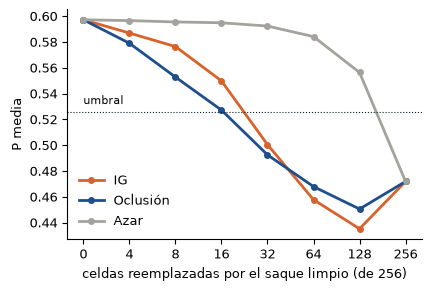

{'metodo': 'IG', 'celdas': 0, 'p_media': 0.5972, 'siguen_marcados': 1.0}
{'metodo': 'IG', 'celdas': 16, 'p_media': 0.5499, 'siguen_marcados': 0.75}
{'metodo': 'IG', 'celdas': 32, 'p_media': 0.5005, 'siguen_marcados': 0.19}
{'metodo': 'Oclusión', 'celdas': 0, 'p_media': 0.5972, 'siguen_marcados': 1.0}
{'metodo': 'Oclusión', 'celdas': 16, 'p_media': 0.5272, 'siguen_marcados': 0.44}
{'metodo': 'Oclusión', 'celdas': 32, 'p_media': 0.4925, 'siguen_marcados': 0.0}
{'metodo': 'Azar', 'celdas': 0, 'p_media': 0.5972, 'siguen_marcados': 1.0}
{'metodo': 'Azar', 'celdas': 16, 'p_media': 0.5949, 'siguen_marcados': 1.0}
{'metodo': 'Azar', 'celdas': 32, 'p_media': 0.5924, 'siguen_marcados': 1.0}


In [9]:
K = [0, 4, 8, 16, 32, 64, 128, 256]  # cells (height, frame) replaced, out of 4 x 64
marked = np.flatnonzero(flagged)
x_marked = x_test[marked]
flat_reference = reference.reshape(-1)


def deletion(order):
    # (len(K), windows) P when the first k cells of each window's order move like the clean serve
    out = []
    for k in K:
        z = x_marked.reshape(len(marked), -1).clone()
        for row, cells in zip(z, order[:, :k]):
            row[cells] = flat_reference[cells]
        with torch.no_grad():
            out.append(f(z.reshape(x_marked.shape)).numpy())
    return np.array(out)


orders = {
    "IG": (-a_test[marked].reshape(len(marked), -1)).argsort(1, kind="stable"),
    "Oclusión": (-np.repeat(fall[marked], serve_model.BIN, 2).reshape(len(marked), -1))
    .argsort(1, kind="stable"),
    "Azar": np.array([rng.permutation(4 * FRAMES) for _ in marked]),
}
colors = {"IG": "#d9622b", "Oclusión": "#1e4f8c", "Azar": "#a3a29c"}
fig, ax = plt.subplots(figsize=(4.2, 2.8), constrained_layout=True)
rows = []
for method, order in orders.items():
    p = deletion(order)
    ax.plot(range(len(K)), p.mean(1), marker="o", ms=4, lw=2, color=colors[method], label=method)
    rows += [{"metodo": method, "celdas": k, "p_media": r(pk.mean(), 4),
              "siguen_marcados": r((pk >= THRESHOLD).mean(), 2)} for k, pk in zip(K, p)]
ax.axhline(THRESHOLD, color="#0b1f2a", lw=0.8, ls=":")
ax.text(0, THRESHOLD + 0.004, "umbral", ha="left", va="bottom", fontsize=8)
ax.set_xticks(range(len(K)), [str(k) for k in K])
ax.set(xlabel="celdas reemplazadas por el saque limpio (de 256)", ylabel="P media")
ax.legend(frameon=False)
fig.savefig(OUT / "fidelidad.png", dpi=200)
plt.show()
save("fidelidad", rows)
for row in rows:
    if row["celdas"] in (0, 16, 32):
        print(row)

## 8. Cómo se le mostraría al jugador

El jugador no necesita un mapa de calor. Necesita ver **qué hizo su mano y cuándo**. La figura compara la altura de la muñeca que lanza en su saque con la del saque limpio y sombrea el tramo de 0.27 s donde IG pone más peso.

Solo se usa un saque de JC, que dio su consentimiento de imagen. No hay cuadros de video.

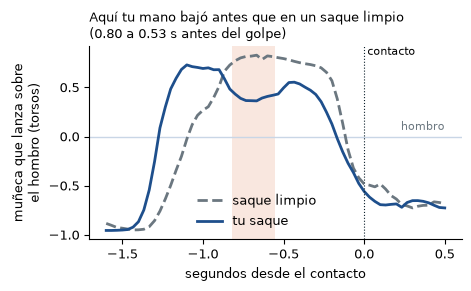

jc-s41: tramo de -0.80 a -0.53 s, atribución 0.028 de 0.155


In [10]:
i = cases["Acierto seguro"]
push = stretches(a_test[i : i + 1])[0, 1]  # tossing wrist, per stretch
start = serve_model.STARTS[push.argmax()]
end = start + serve_model.BIN
fig, ax = plt.subplots(figsize=(4.6, 2.8), constrained_layout=True)
ax.axvspan(TIME[start] - 0.5 / dataset.FPS, TIME[end - 1] + 0.5 / dataset.FPS,
           color="#d9622b", alpha=0.15, lw=0)
ax.axhline(0, color="#c9d6e6", lw=1)
ax.plot(TIME, reference[0, 1].numpy(), color="#6b7780", ls="--", lw=2, label="saque limpio")
ax.plot(TIME, x_test[i, 1].numpy(), color="#1e4f8c", lw=2, label="tu saque")
ax.axvline(0, color="#0b1f2a", lw=0.8, ls=":")
ax.text(0.02, ax.get_ylim()[1], "contacto", va="top", fontsize=8)
ax.text(TIME[-1], 0.04, "hombro", ha="right", va="bottom", fontsize=8,
        color="#6b7780")
ax.set_title(f"Aquí tu mano bajó antes que en un saque limpio\n"
             f"({-TIME[start]:.2f} a {-TIME[end]:.2f} s antes del golpe)", loc="left", fontsize=9)
ax.set(xlabel="segundos desde el contacto", ylabel="muñeca que lanza sobre\nel hombro (torsos)")
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.45, 0))
fig.savefig(OUT / "audiencia.png", dpi=200)
plt.show()
print(f"{video[i]}: tramo de {TIME[start]:+.2f} a {TIME[end]:+.2f} s, "
      f"atribución {push.max():.3f} de {a_test[i].sum():.3f}")

## 9. Costo

Se mide el tiempo de explicar un saque en esta Mac (CPU), con la mediana de los 18 saques de prueba.

Estos tiempos solo se imprimen y no van a ningún CSV, porque cambian de una corrida a otra.

In [11]:
def milliseconds(run):
    times = []
    for j in range(len(x_test)):
        begin = time.perf_counter()
        run(j)
        times.append(time.perf_counter() - begin)
    return 1000 * np.median(times)


ig_ms = milliseconds(lambda j: attribute(x_test[j : j + 1]))
occlusion_ms = milliseconds(lambda j: serve_model.occlusion(m1e, mx[j : j + 1], mm[j : j + 1]))
print(f"IG ({N_STEPS} pasos): {ig_ms:.0f} ms por saque; oclusión (32 reemplazos): "
      f"{occlusion_ms:.0f} ms por saque; el análisis completo de la app tarda 3 a 6 s")

IG (64 pasos): 25 ms por saque; oclusión (32 reemplazos): 16 ms por saque; el análisis completo de la app tarda 3 a 6 s
